In [1]:

# MONSOON MIND
# Step 1: Import required libraries

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime

print("MONSOON MIND - Environment initialized!")
print("Python libraries imported successfully.")


MONSOON MIND - Environment initialized!
Python libraries imported successfully.


In [2]:

# Step 2: Download historical solar and weather data for Goa

url = "https://re.jrc.ec.europa.eu/api/v5_3/seriescalc"

params = {
    "lat": 15.4909,
    "lon": 73.8278,
    "startyear": 2014,
    "endyear": 2023,
    "pvcalculation": 1,
    "peakpower": 1,
    "pvtechchoice": "crystSi",
    "mountingplace": "building",
    "loss": 14,
    "angle": 15,
    "aspect": 0,
    "outputformat": "json"
}

response = requests.get(url, params=params, timeout=120)

response.raise_for_status()

result = response.json()

print("API request completed!")
print("Response status:", response.status_code)
print("Available response sections:", result.keys())


API request completed!
Response status: 200
Available response sections: dict_keys(['inputs', 'outputs', 'meta'])


In [3]:

# Step 3: Extract hourly records

hourly_data = result["outputs"]["hourly"]

data = pd.DataFrame(hourly_data)

data["time"] = pd.to_datetime(
    data["time"],
    format="%Y%m%d:%H%M",
    utc=True
)

data = data.sort_values("time").reset_index(drop=True)

print("Dataset downloaded successfully!")
print("Dataset shape:", data.shape)

display(data.head())
print("\nDataset columns:")
print(data.columns.tolist())


Dataset downloaded successfully!
Dataset shape: (87648, 7)


,time,P,G(i),H_sun,T2m,WS10m,Int
0,2014-01-01 00:30:00+00:00,0.00,0.00,0.00,23.41,3.03,0.0
1,2014-01-01 01:30:00+00:00,0.00,0.00,-1.13,23.24,3.24,0.0
2,2014-01-01 02:30:00+00:00,154.42,223.30,11.88,23.64,3.52,0.0
3,2014-01-01 03:30:00+00:00,352.29,461.61,24.23,24.17,3.93,0.0
4,2014-01-01 04:30:00+00:00,516.31,678.64,35.44,24.81,4.55,0.0



Dataset columns:
['time', 'P', 'G(i)', 'H_sun', 'T2m', 'WS10m', 'Int']


In [4]:

# CELL 4: DATA QUALITY CHECK

print("Dataset information:")
print(data.info())

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate timestamps:")
print(data["time"].duplicated().sum())

print("\nStatistical summary:")
display(data.describe().round(2))

print("\nDate range:")
print("Start:", data["time"].min())
print("End:", data["time"].max())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87648 entries, 0 to 87647
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype              
---  ------  --------------  -----              
 0   time    87648 non-null  datetime64[ns, UTC]
 1   P       87648 non-null  float64            
 2   G(i)    87648 non-null  float64            
 3   H_sun   87648 non-null  float64            
 4   T2m     87648 non-null  float64            
 5   WS10m   87648 non-null  float64            
 6   Int     87648 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(6)
memory usage: 4.7 MB
None

Missing values:
time     0
P        0
G(i)     0
H_sun    0
T2m      0
WS10m    0
Int      0
dtype: int64

Duplicate timestamps:
0

Statistical summary:


,P,G(i),H_sun,T2m,WS10m,Int
count,87648.00,87648.00,87648.00,87648.00,87648.00,87648.0
mean,162.36,224.67,19.84,27.23,3.96,0.0
std,225.98,311.70,25.84,1.68,3.18,0.0
min,0.00,0.00,-6.89,20.35,0.00,0.0
25%,0.00,0.00,0.00,26.07,2.41,0.0
50%,0.00,0.00,0.00,27.06,3.59,0.0
75%,331.46,438.94,39.69,28.46,4.90,0.0
max,780.88,1080.63,85.20,33.66,37.79,0.0



Date range:
Start: 2014-01-01 00:30:00+00:00
End: 2023-12-31 23:30:00+00:00


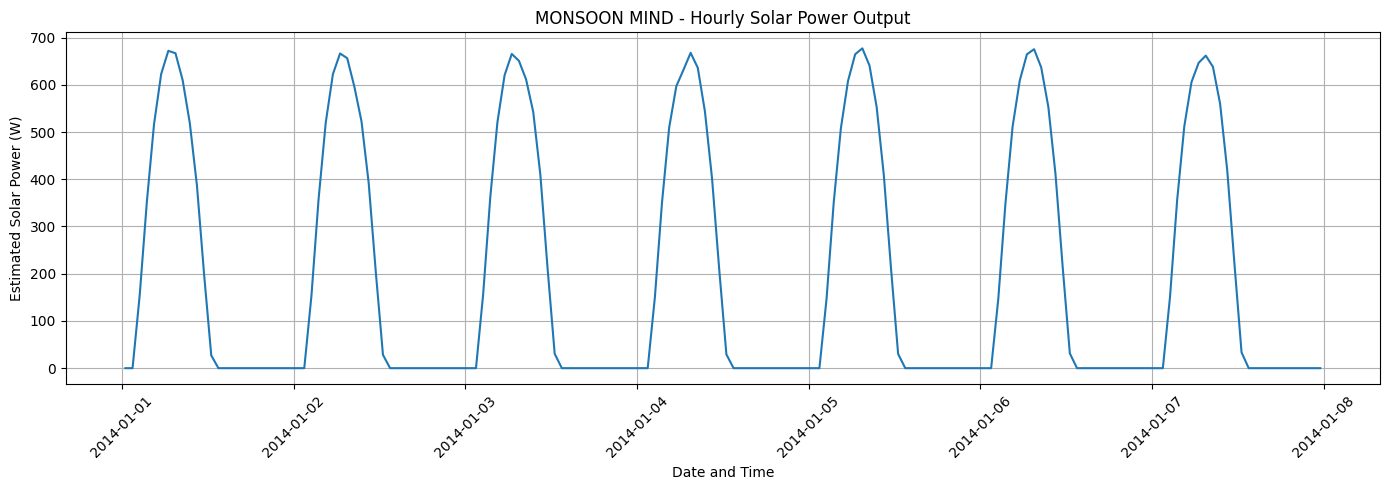

In [5]:

# CELL 5: SOLAR GENERATION VISUALISATION

import matplotlib.pyplot as plt

# Select the first 7 days
sample = data.iloc[:168]

plt.figure(figsize=(14, 5))
plt.plot(sample["time"], sample["P"])
plt.title("MONSOON MIND - Hourly Solar Power Output")
plt.xlabel("Date and Time")
plt.ylabel("Estimated Solar Power (W)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


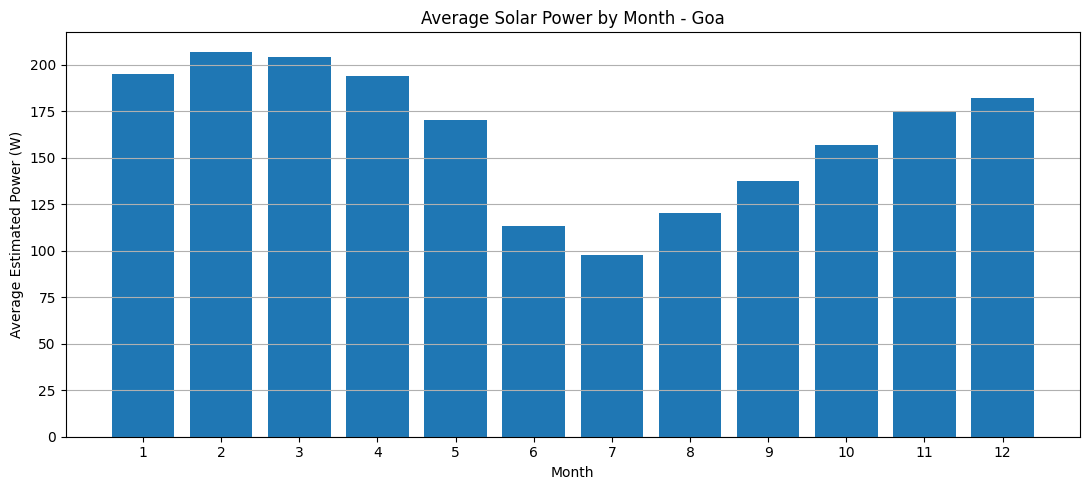

In [6]:

# CELL 6: MONTHLY SOLAR GENERATION PATTERN

data["month"] = data["time"].dt.month

monthly_generation = data.groupby("month")["P"].mean()

plt.figure(figsize=(11, 5))
plt.bar(monthly_generation.index, monthly_generation.values)
plt.title("Average Solar Power by Month - Goa")
plt.xlabel("Month")
plt.ylabel("Average Estimated Power (W)")
plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [7]:

# CELL 7: SEASONAL ANALYSIS

data["month"] = data["time"].dt.month

def classify_season(month):
    if month in [6, 7, 8, 9]:
        return "Monsoon"
    elif month in [10, 11, 12, 1, 2, 3, 4, 5]:
        return "Non-Monsoon"

data["season"] = data["month"].apply(classify_season)

season_summary = data.groupby("season").agg(
    Average_Power=("P", "mean"),
    Average_Irradiance=("G(i)", "mean"),
    Average_Temperature=("T2m", "mean"),
    Average_Wind_Speed=("WS10m", "mean"),
    Total_Records=("P", "count")
)

display(season_summary.round(2))


,Average_Power,Average_Irradiance,Average_Temperature,Average_Wind_Speed,Total_Records
season,,,,,
Monsoon,116.93,158.78,26.60,4.50,29280
Non-Monsoon,185.16,257.72,27.54,3.69,58368


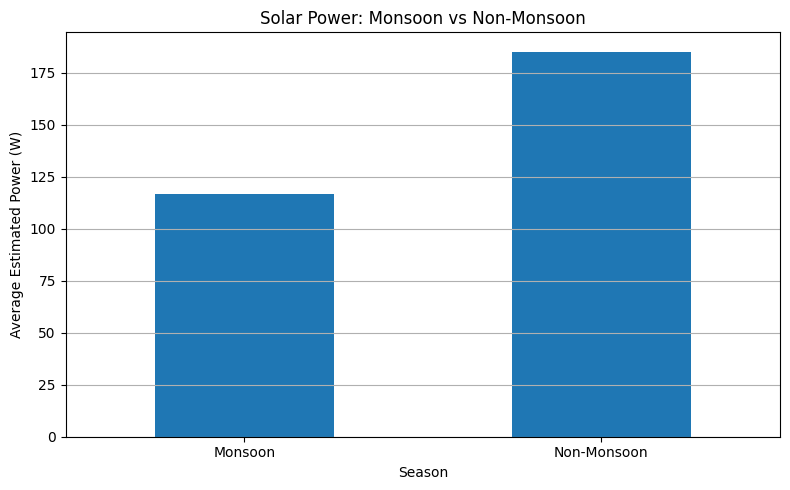

In [8]:

# CELL 8: MONSOON VS NON-MONSOON

import matplotlib.pyplot as plt

season_power = data.groupby("season")["P"].mean()

plt.figure(figsize=(8, 5))
season_power.plot(kind="bar")
plt.title("Solar Power: Monsoon vs Non-Monsoon")
plt.xlabel("Season")
plt.ylabel("Average Estimated Power (W)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


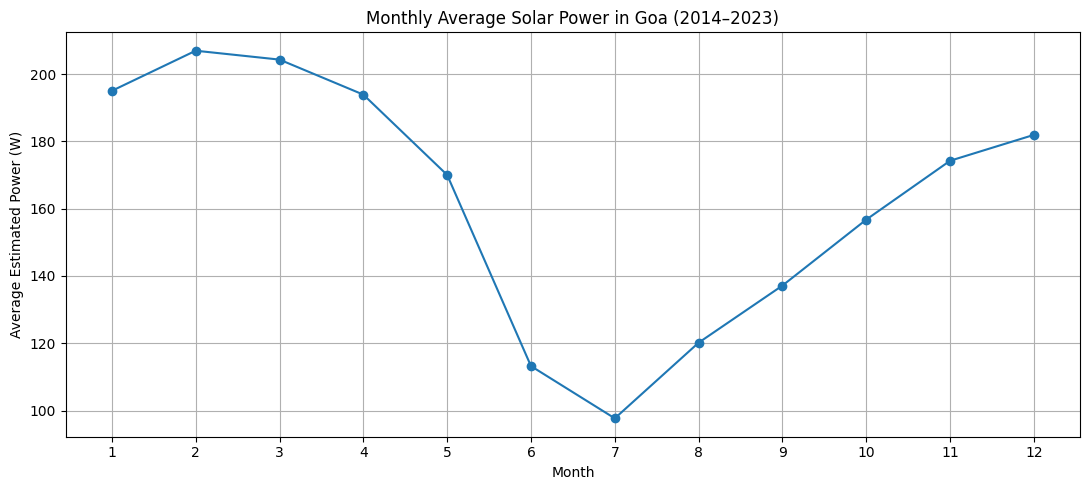

In [9]:

# CELL 9: MONTHLY SOLAR POWER PATTERN

monthly_power = data.groupby("month")["P"].mean()

plt.figure(figsize=(11, 5))
plt.plot(monthly_power.index, monthly_power.values, marker="o")
plt.title("Monthly Average Solar Power in Goa (2014–2023)")
plt.xlabel("Month")
plt.ylabel("Average Estimated Power (W)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()


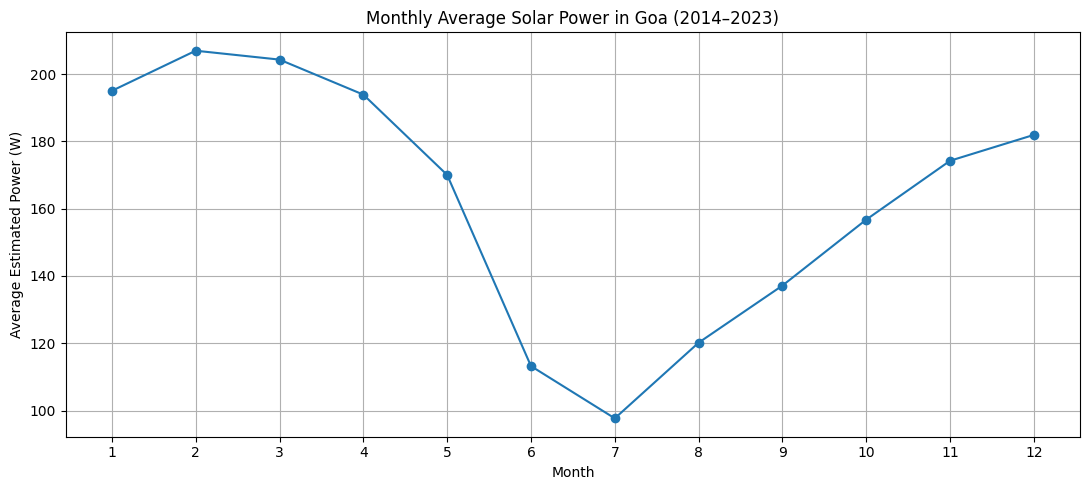

,P
month,
1,195.03
2,206.95
3,204.31
4,193.90
5,170.03
6,113.22
7,97.69
8,120.18
9,137.15


In [10]:

# CELL 9: MONTHLY SOLAR GENERATION

monthly_power = data.groupby("month")["P"].mean()

plt.figure(figsize=(11, 5))
plt.plot(monthly_power.index, monthly_power.values, marker="o")
plt.title("Monthly Average Solar Power in Goa (2014–2023)")
plt.xlabel("Month")
plt.ylabel("Average Estimated Power (W)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

display(monthly_power.round(2))


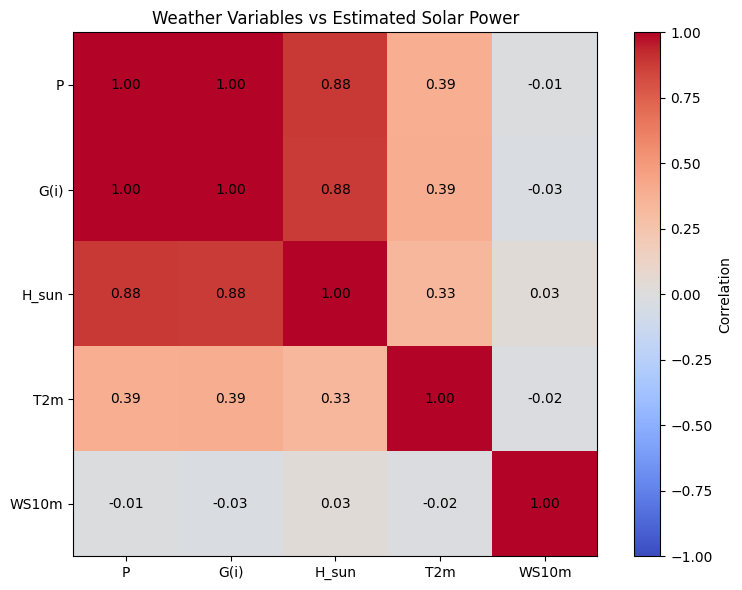

,P
P,1.000000
G(i),0.998806
H_sun,0.883080
T2m,0.385122
WS10m,-0.014983


In [11]:

# CELL 10: CORRELATION ANALYSIS

correlation_columns = ["P", "G(i)", "H_sun", "T2m", "WS10m"]

correlation = data[correlation_columns].corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_columns)), correlation_columns)
plt.yticks(range(len(correlation_columns)), correlation_columns)

for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Weather Variables vs Estimated Solar Power")
plt.tight_layout()
plt.show()

display(correlation["P"].sort_values(ascending=False))


In [12]:

# CELL 11: FEATURE ENGINEERING AND CHRONOLOGICAL SPLIT

from sklearn.model_selection import train_test_split

# Sort data chronologically
data = data.sort_values("time").reset_index(drop=True)

# Create calendar features
data["hour"] = data["time"].dt.hour
data["day_of_year"] = data["time"].dt.dayofyear
data["month"] = data["time"].dt.month

# Define target
target = "P"

# Experiment 1: Includes irradiance
features_full = [
    "G(i)", "H_sun", "T2m", "WS10m",
    "hour", "day_of_year", "month"
]

# Experiment 2: Excludes irradiance
features_weather = [
    "H_sun", "T2m", "WS10m",
    "hour", "day_of_year", "month"
]

# Chronological split
train_data = data[data["time"].dt.year <= 2021].copy()
validation_data = data[data["time"].dt.year == 2022].copy()
test_data = data[data["time"].dt.year == 2023].copy()

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Testing records:", len(test_data))

print("\nTraining period:",
      train_data["time"].min(), "to", train_data["time"].max())

print("\nValidation period:",
      validation_data["time"].min(), "to", validation_data["time"].max())

print("\nTesting period:",
      test_data["time"].min(), "to", test_data["time"].max())


Training records: 70128
Validation records: 8760
Testing records: 8760

Training period: 2014-01-01 00:30:00+00:00 to 2021-12-31 23:30:00+00:00

Validation period: 2022-01-01 00:30:00+00:00 to 2022-12-31 23:30:00+00:00

Testing period: 2023-01-01 00:30:00+00:00 to 2023-12-31 23:30:00+00:00


In [13]:

# CELL 12: RANDOM FOREST BASELINE

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use the full feature set for the first experiment
X_train = train_data[features_full]
y_train = train_data[target]

X_val = validation_data[features_full]
y_val = validation_data[target]

# Train model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Validation predictions
val_predictions = rf_model.predict(X_val)

# Evaluation
mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")
print(f"MAE:  {mae:.2f} W")
print(f"RMSE: {rmse:.2f} W")
print(f"R²:   {r2:.4f}")


RANDOM FOREST - VALIDATION RESULTS
----------------------------------
MAE:  0.55 W
RMSE: 1.18 W
R²:   1.0000


In [14]:

# CELL 13: RANDOM FOREST WITHOUT IRRADIANCE

X_train_weather = train_data[features_weather]
X_val_weather = validation_data[features_weather]

y_train = train_data["P"]
y_val = validation_data["P"]

rf_weather_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_weather_model.fit(X_train_weather, y_train)

weather_predictions = rf_weather_model.predict(X_val_weather)

mae_weather = mean_absolute_error(y_val, weather_predictions)
rmse_weather = np.sqrt(
    mean_squared_error(y_val, weather_predictions)
)
r2_weather = r2_score(y_val, weather_predictions)

print("RANDOM FOREST - WITHOUT IRRADIANCE")
print("----------------------------------")
print(f"MAE:  {mae_weather:.2f} W")
print(f"RMSE: {rmse_weather:.2f} W")
print(f"R²:   {r2_weather:.4f}")


RANDOM FOREST - WITHOUT IRRADIANCE
----------------------------------
MAE:  23.34 W
RMSE: 52.20 W
R²:   0.9452


In [15]:

# CELL 14: MODEL COMPARISON

comparison = pd.DataFrame({
    "Experiment": [
        "With Irradiance",
        "Without Irradiance"
    ],
    "MAE": [
        mae,
        mae_weather
    ],
    "RMSE": [
        rmse,
        rmse_weather
    ],
    "R2": [
        r2,
        r2_weather
    ]
})

display(comparison.round(4))


,Experiment,MAE,RMSE,R2
0,With Irradiance,0.5544,1.1806,1.0000
1,Without Irradiance,23.3417,52.2000,0.9452


In [16]:

# CELL 15: MONTHLY MODEL PERFORMANCE

validation_results = validation_data[["time", "P"]].copy()

validation_results["Predicted_P"] = weather_predictions

validation_results["Absolute_Error"] = abs(
    validation_results["P"] -
    validation_results["Predicted_P"]
)

validation_results["Month"] = (
    validation_results["time"].dt.month
)

monthly_errors = validation_results.groupby("Month").agg(
    Actual_Average=("P", "mean"),
    Predicted_Average=("Predicted_P", "mean"),
    MAE=("Absolute_Error", "mean")
)

display(monthly_errors.round(2))


,Actual_Average,Predicted_Average,MAE
Month,,,
1,193.45,190.96,12.48
2,209.65,205.21,9.70
3,190.78,200.45,18.18
4,181.62,189.75,15.54
5,150.86,169.89,31.71
6,118.62,107.44,30.54
7,98.01,90.07,28.38
8,119.29,117.71,31.36
9,146.28,132.95,33.08


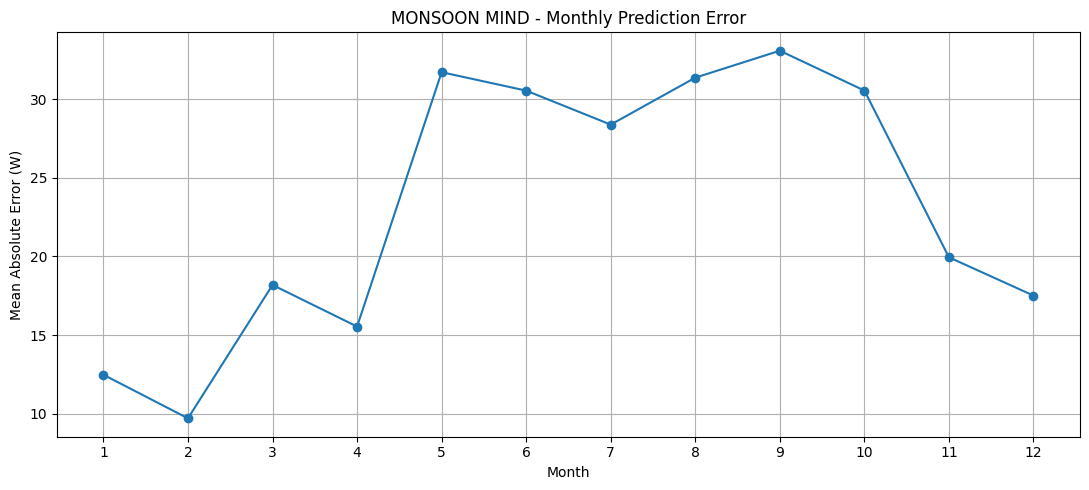

In [17]:

# CELL 16: MONTHLY ERROR VISUALISATION

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_errors.index,
    monthly_errors["MAE"],
    marker="o"
)

plt.title("MONSOON MIND - Monthly Prediction Error")
plt.xlabel("Month")
plt.ylabel("Mean Absolute Error (W)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()


In [21]:

# CELL 18: XGBOOST MODEL
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_weather,
    y_train,
    eval_set=[(X_val_weather, y_val)],
    verbose=False
)

xgb_predictions = xgb_model.predict(X_val_weather)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))
xgb_r2 = r2_score(y_val, xgb_predictions)

print("XGBOOST - VALIDATION RESULTS")
print("----------------------------")
print(f"MAE:  {xgb_mae:.2f} W")
print(f"RMSE: {xgb_rmse:.2f} W")
print(f"R²:   {xgb_r2:.4f}")


XGBOOST - VALIDATION RESULTS
----------------------------
MAE:  24.31 W
RMSE: 52.06 W
R²:   0.9455


In [22]:

# CELL 19: RANDOM FOREST VS XGBOOST

model_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [mae_weather, xgb_mae],
    "RMSE": [rmse_weather, xgb_rmse],
    "R2": [r2_weather, xgb_r2]
})

display(model_comparison.round(4))


,Model,MAE,RMSE,R2
0,Random Forest,23.3417,52.2000,0.9452
1,XGBoost,24.3106,52.0609,0.9455


In [23]:

# CELL 20: PREPARE UNSEEN TEST DATA

X_test_weather = test_data[features_weather]
y_test = test_data["P"]

print("Test dataset shape:", X_test_weather.shape)
print("Test period:",
      test_data["time"].min(),
      "to",
      test_data["time"].max())


Test dataset shape: (8760, 6)
Test period: 2023-01-01 00:30:00+00:00 to 2023-12-31 23:30:00+00:00


In [24]:

# CELL 21: RANDOM FOREST TEST EVALUATION

rf_test_predictions = rf_weather_model.predict(X_test_weather)

rf_test_mae = mean_absolute_error(
    y_test, rf_test_predictions
)

rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_test_predictions)
)

rf_test_r2 = r2_score(
    y_test, rf_test_predictions
)

print("RANDOM FOREST - 2023 TEST RESULTS")
print("---------------------------------")
print(f"MAE:  {rf_test_mae:.2f} W")
print(f"RMSE: {rf_test_rmse:.2f} W")
print(f"R²:   {rf_test_r2:.4f}")


RANDOM FOREST - 2023 TEST RESULTS
---------------------------------
MAE:  18.72 W
RMSE: 42.11 W
R²:   0.9670


In [25]:

# CELL 22: XGBOOST TEST EVALUATION

xgb_test_predictions = xgb_model.predict(X_test_weather)

xgb_test_mae = mean_absolute_error(
    y_test, xgb_test_predictions
)

xgb_test_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_test_predictions)
)

xgb_test_r2 = r2_score(
    y_test, xgb_test_predictions
)

print("XGBOOST - 2023 TEST RESULTS")
print("---------------------------")
print(f"MAE:  {xgb_test_mae:.2f} W")
print(f"RMSE: {xgb_test_rmse:.2f} W")
print(f"R²:   {xgb_test_r2:.4f}")


XGBOOST - 2023 TEST RESULTS
---------------------------
MAE:  19.30 W
RMSE: 41.06 W
R²:   0.9686


In [26]:

# CELL 23: FINAL TEST COMPARISON

test_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [rf_test_mae, xgb_test_mae],
    "RMSE": [rf_test_rmse, xgb_test_rmse],
    "R2": [rf_test_r2, xgb_test_r2]
})

display(test_comparison.round(4))


,Model,MAE,RMSE,R2
0,Random Forest,18.7187,42.1141,0.9670
1,XGBoost,19.3012,41.0585,0.9686


In [27]:

# CELL 24: MONTHLY PERFORMANCE ON UNSEEN 2023 DATA

test_results = test_data[["time", "P"]].copy()

test_results["RF_Predicted"] = rf_test_predictions
test_results["XGB_Predicted"] = xgb_test_predictions

test_results["Month"] = test_results["time"].dt.month

test_results["RF_Error"] = abs(
    test_results["P"] - test_results["RF_Predicted"]
)

test_results["XGB_Error"] = abs(
    test_results["P"] - test_results["XGB_Predicted"]
)

monthly_test_performance = test_results.groupby("Month").agg(
    Actual_Average=("P", "mean"),
    RF_MAE=("RF_Error", "mean"),
    XGB_MAE=("XGB_Error", "mean")
)

display(monthly_test_performance.round(2))


,Actual_Average,RF_MAE,XGB_MAE
Month,,,
1,202.05,9.58,9.64
2,211.64,6.94,7.22
3,215.76,13.13,12.74
4,197.89,10.56,10.85
5,185.29,19.71,19.96
6,133.37,27.09,29.14
7,78.46,34.40,34.94
8,152.49,22.47,23.81
9,132.07,29.15,29.59


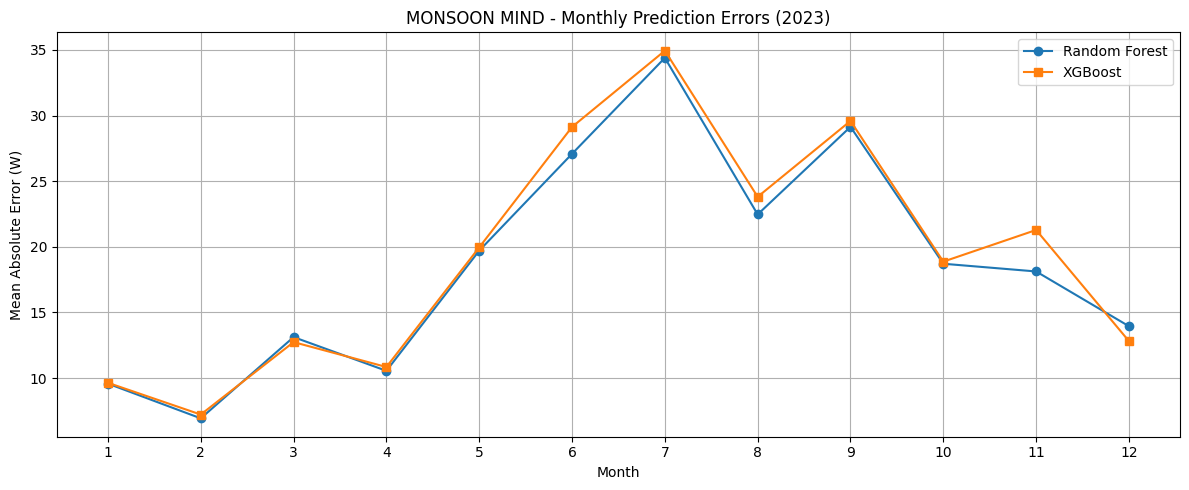

In [28]:

# CELL 25: MONTHLY TEST ERROR COMPARISON

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_test_performance.index,
    monthly_test_performance["RF_MAE"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    monthly_test_performance.index,
    monthly_test_performance["XGB_MAE"],
    marker="s",
    label="XGBoost"
)

plt.title("MONSOON MIND - Monthly Prediction Errors (2023)")
plt.xlabel("Month")
plt.ylabel("Mean Absolute Error (W)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [29]:

# CELL 26: INSTALL SHAP

!pip -q install shap

import shap

print("SHAP installed successfully.")


SHAP installed successfully.


In [30]:

# CELL 27: SHAP EXPLAINABILITY

# Select a reproducible sample
X_shap = X_test_weather.sample(
    n=1000,
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_weather_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated!")
print("SHAP array shape:", shap_values.shape)


SHAP values calculated!
SHAP array shape: (1000, 6)


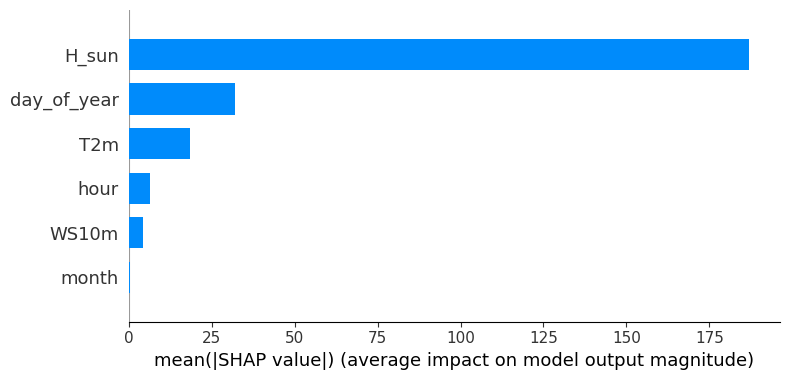

In [31]:

# CELL 28: SHAP FEATURE IMPORTANCE

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar"
)


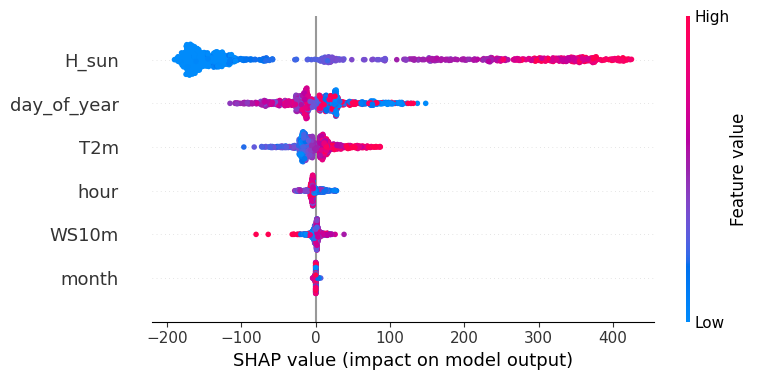

In [32]:

# CELL 29: SHAP SUMMARY PLOT

shap.summary_plot(
    shap_values,
    X_shap
)


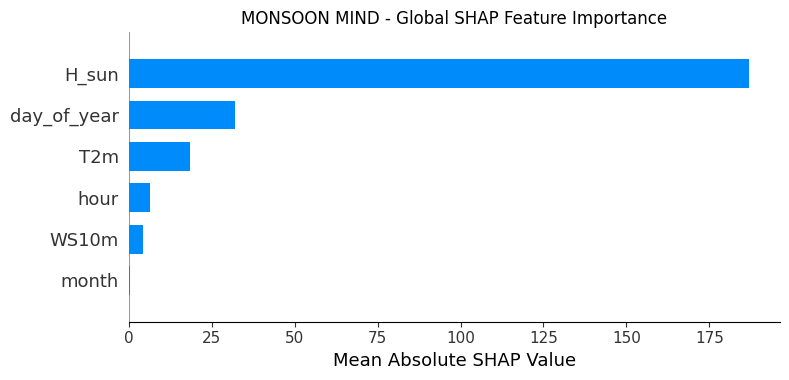

In [33]:
# CELL 30: GLOBAL SHAP FEATURE IMPORTANCE

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title("MONSOON MIND - Global SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()
plt.show()

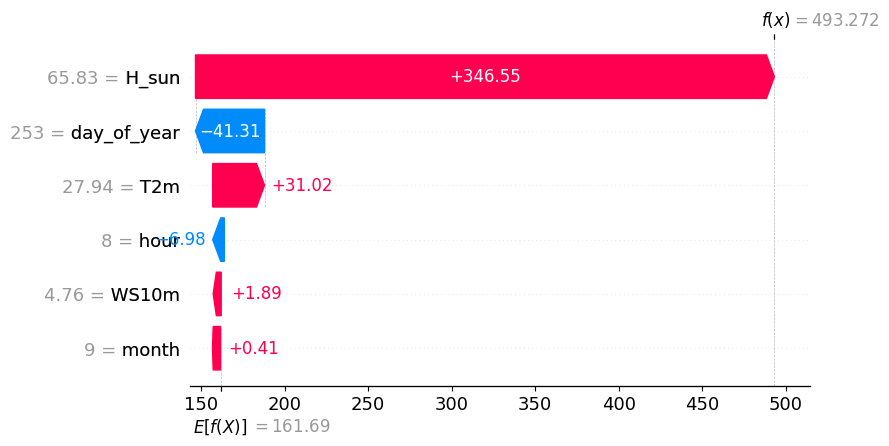

In [34]:
# CELL 31: INDIVIDUAL PREDICTION EXPLANATION

sample_index = 0

single_explanation = shap.Explanation(
    values=shap_values[sample_index],
    base_values=explainer.expected_value,
    data=X_shap.iloc[sample_index].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(single_explanation)

,Feature,Mean_Absolute_SHAP
0,H_sun,186.930
4,day_of_year,31.998
1,T2m,18.529
3,hour,6.313
2,WS10m,4.197
5,month,0.517


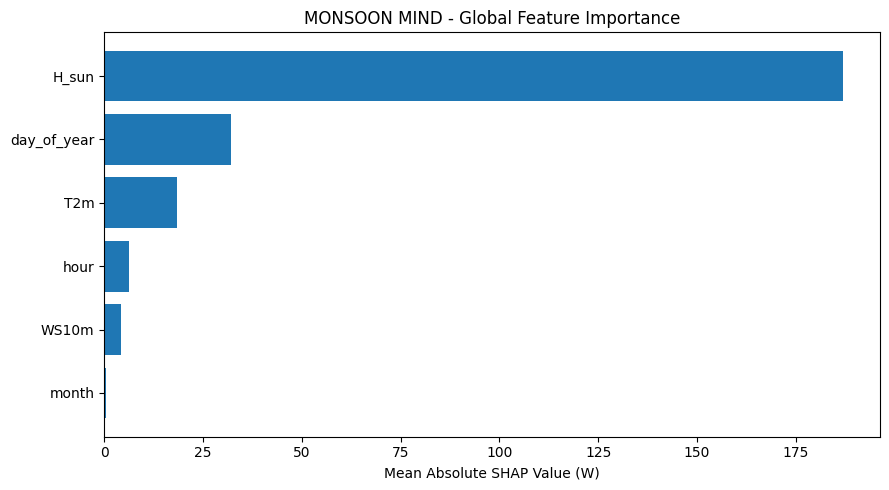

In [35]:
# FINAL CELL: GLOBAL SHAP IMPORTANCE

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": abs(shap_values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

display(shap_importance.round(3))

plt.figure(figsize=(9, 5))
plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance["Mean_Absolute_SHAP"][::-1]
)
plt.xlabel("Mean Absolute SHAP Value (W)")
plt.title("MONSOON MIND - Global Feature Importance")
plt.tight_layout()
plt.show()

In [36]:
# CELL 32: DASHBOARD LIBRARIES

!pip -q install plotly ipywidgets

import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display, HTML
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

print("MONSOON MIND dashboard libraries ready.")

MONSOON MIND dashboard libraries ready.


In [37]:
# CELL 33: PREPARE DASHBOARD DATA

# Actual and predicted values for unseen 2023 data
dashboard_data = test_data[["time", "P"]].copy()

dashboard_data["RF_Predicted"] = np.asarray(rf_test_predictions)
dashboard_data["XGB_Predicted"] = np.asarray(xgb_test_predictions)

dashboard_data["Month"] = dashboard_data["time"].dt.month
dashboard_data["Month_Name"] = dashboard_data["time"].dt.strftime("%b")

dashboard_data["RF_Error"] = abs(
    dashboard_data["P"] - dashboard_data["RF_Predicted"]
)

dashboard_data["XGB_Error"] = abs(
    dashboard_data["P"] - dashboard_data["XGB_Predicted"]
)

# Monthly generation and prediction error
monthly_dashboard = dashboard_data.groupby("Month").agg(
    Actual=("P", "mean"),
    RF_Predicted=("RF_Predicted", "mean"),
    XGB_Predicted=("XGB_Predicted", "mean"),
    RF_MAE=("RF_Error", "mean"),
    XGB_MAE=("XGB_Error", "mean")
).reset_index()

monthly_dashboard["Month_Name"] = pd.to_datetime(
    monthly_dashboard["Month"], format="%m"
).dt.strftime("%b")

# Model evaluation metrics
rf_metrics = {
    "MAE": mean_absolute_error(
        dashboard_data["P"], dashboard_data["RF_Predicted"]
    ),
    "RMSE": np.sqrt(mean_squared_error(
        dashboard_data["P"], dashboard_data["RF_Predicted"]
    )),
    "R2": r2_score(
        dashboard_data["P"], dashboard_data["RF_Predicted"]
    )
}

xgb_metrics = {
    "MAE": mean_absolute_error(
        dashboard_data["P"], dashboard_data["XGB_Predicted"]
    ),
    "RMSE": np.sqrt(mean_squared_error(
        dashboard_data["P"], dashboard_data["XGB_Predicted"]
    )),
    "R2": r2_score(
        dashboard_data["P"], dashboard_data["XGB_Predicted"]
    )
}

print("Dashboard data prepared successfully.")
print("2023 records:", len(dashboard_data))
print("Random Forest:", rf_metrics)
print("XGBoost:", xgb_metrics)

Dashboard data prepared successfully.
2023 records: 8760
Random Forest: {'MAE': 18.718728872519257, 'RMSE': np.float64(42.1140650393983), 'R2': 0.9670071886155638}
XGBoost: {'MAE': 19.30118129501705, 'RMSE': np.float64(41.05853053464504), 'R2': 0.9686403070709654}


In [38]:
# CELL 34: MONSOON MIND INTERACTIVE DASHBOARD

# Dashboard heading
display(HTML("""
<div style="
    background: linear-gradient(120deg, #071522, #12354A);
    padding: 30px;
    border-radius: 16px;
    color: white;
    font-family: Arial;
    margin-bottom: 18px;
">
    <div style="font-size: 13px; letter-spacing: 3px; color: #8FD3E8;">
        AI-POWERED SOLAR RESILIENCE
    </div>
    <h1 style="margin: 10px 0; font-size: 34px;">
        MONSOON MIND
    </h1>
    <div style="font-size: 15px; color: #D0E3EC;">
        Historical Solar Analytics & Explainable Machine Learning
    </div>
    <div style="font-size: 12px; color: #8FD3E8; margin-top: 14px;">
        GOA, INDIA · PVGIS DATA · 2014–2023
    </div>
</div>
"""))

# Metric cards
display(HTML(f"""
<div style="display:flex; flex-wrap:wrap; gap:12px;
font-family:Arial; margin-bottom:20px;">

<div style="flex:1; min-width:145px; background:#102638;
padding:18px; border-radius:12px; color:white;">
<div style="font-size:12px; color:#9FC4D4;">TEST DATA</div>
<div style="font-size:27px; font-weight:bold;">8,760</div>
<div style="font-size:12px; color:#B6CFDA;">Hourly observations</div>
</div>

<div style="flex:1; min-width:145px; background:#102638;
padding:18px; border-radius:12px; color:white;">
<div style="font-size:12px; color:#9FC4D4;">RF TEST MAE</div>
<div style="font-size:27px; font-weight:bold;">{rf_metrics['MAE']:.2f} W</div>
<div style="font-size:12px; color:#B6CFDA;">2023 unseen data</div>
</div>

<div style="flex:1; min-width:145px; background:#102638;
padding:18px; border-radius:12px; color:white;">
<div style="font-size:12px; color:#9FC4D4;">RF TEST R²</div>
<div style="font-size:27px; font-weight:bold;">{rf_metrics['R2']:.4f}</div>
<div style="font-size:12px; color:#B6CFDA;">Coefficient of determination</div>
</div>

<div style="flex:1; min-width:145px; background:#102638;
padding:18px; border-radius:12px; color:white;">
<div style="font-size:12px; color:#9FC4D4;">DATA PERIOD</div>
<div style="font-size:27px; font-weight:bold;">10 Years</div>
<div style="font-size:12px; color:#B6CFDA;">2014–2023</div>
</div>

</div>
"""))

# ---------- TAB 1: OVERVIEW ----------

fig_overview = go.Figure()

fig_overview.add_trace(go.Scatter(
    x=monthly_dashboard["Month_Name"],
    y=monthly_dashboard["Actual"],
    mode="lines+markers",
    name="Actual PVGIS power",
    line=dict(width=3)
))

fig_overview.add_trace(go.Scatter(
    x=monthly_dashboard["Month_Name"],
    y=monthly_dashboard["RF_Predicted"],
    mode="lines+markers",
    name="Random Forest",
    line=dict(dash="dash", width=2)
))

fig_overview.add_trace(go.Scatter(
    x=monthly_dashboard["Month_Name"],
    y=monthly_dashboard["XGB_Predicted"],
    mode="lines+markers",
    name="XGBoost",
    line=dict(dash="dot", width=2)
))

fig_overview.update_layout(
    title="Monthly Solar Power: Actual vs Model Estimates",
    xaxis_title="Month",
    yaxis_title="Average power (W)",
    template="plotly_dark",
    height=450,
    hovermode="x unified"
)

# Model comparison
fig_comparison = go.Figure()

for model_name, metrics in [
    ("Random Forest", rf_metrics),
    ("XGBoost", xgb_metrics)
]:
    fig_comparison.add_trace(go.Bar(
        name=model_name,
        x=["MAE (W)", "RMSE (W)"],
        y=[metrics["MAE"], metrics["RMSE"]]
    ))

fig_comparison.update_layout(
    title="Model Performance Comparison — 2023",
    barmode="group",
    template="plotly_dark",
    height=400
)

# ---------- TAB 2: SOLAR ANALYTICS ----------

fig_season = go.Figure()

fig_season.add_trace(go.Bar(
    x=["Non-monsoon", "Monsoon"],
    y=[185.16, 116.93],
    text=["185.16 W", "116.93 W"],
    textposition="outside",
    name="Average PVGIS power"
))

fig_season.update_layout(
    title="Historical Seasonal Solar Power Comparison",
    yaxis_title="Average power (W)",
    template="plotly_dark",
    height=400
)

fig_monthly = px.bar(
    monthly_dashboard,
    x="Month_Name",
    y="Actual",
    title="2023 Monthly Average PVGIS Power",
    labels={
        "Month_Name": "Month",
        "Actual": "Average power (W)"
    },
    template="plotly_dark"
)

fig_monthly.update_layout(height=400)

# ---------- TAB 3: MONSOON INTELLIGENCE ----------

fig_error = go.Figure()

fig_error.add_trace(go.Scatter(
    x=monthly_dashboard["Month_Name"],
    y=monthly_dashboard["RF_MAE"],
    mode="lines+markers",
    name="Random Forest MAE",
    line=dict(width=3)
))

fig_error.add_trace(go.Scatter(
    x=monthly_dashboard["Month_Name"],
    y=monthly_dashboard["XGB_MAE"],
    mode="lines+markers",
    name="XGBoost MAE",
    line=dict(width=3, dash="dash")
))

fig_error.update_layout(
    title="Monthly Prediction Error — Unseen 2023 Data",
    xaxis_title="Month",
    yaxis_title="Mean Absolute Error (W)",
    template="plotly_dark",
    height=450,
    hovermode="x unified"
)

# ---------- TAB 4: EXPLAINABLE AI ----------

fig_shap = px.bar(
    shap_importance.sort_values("Mean_Absolute_SHAP"),
    x="Mean_Absolute_SHAP",
    y="Feature",
    orientation="h",
    title="Global SHAP Feature Importance",
    labels={
        "Mean_Absolute_SHAP": "Mean Absolute SHAP Value (W)",
        "Feature": "Model feature"
    },
    template="plotly_dark"
)

fig_shap.update_layout(height=450)

# ---------- INTERACTIVE TABS ----------

tab_output = widgets.Output()

tab_names = [
    "Overview",
    "Solar Analytics",
    "Monsoon Intelligence",
    "Explainable AI"
]

tab = widgets.Tab()
tab.children = [widgets.Output() for _ in tab_names]

for i, name in enumerate(tab_names):
    tab.set_title(i, name)

with tab.children[0]:
    display(fig_overview)
    display(fig_comparison)

with tab.children[1]:
    display(fig_season)
    display(fig_monthly)

with tab.children[2]:
    display(fig_error)

with tab.children[3]:
    display(fig_shap)

display(tab)

# Footer
display(HTML("""
<div style="
    background:#102638;
    padding:16px;
    border-radius:10px;
    color:#B6CFDA;
    font-family:Arial;
    font-size:12px;
    margin-top:16px;
">
    <b style="color:#8FD3E8;">MONSOON MIND</b><br>
    Historical-data research prototype. PVGIS values are modelled estimates,
    not measured household generation. This dashboard does not provide
    live weather forecasts or real-time solar monitoring.
</div>
"""))